# Cloud infrastructure: measured baseline

This notebook reads the saved, non-private measurements and rebuilds the figures. It does not
train models or launch cloud resources. Run it from a clone with Python, pandas, matplotlib and
nbformat installed. In Colab, clone the repository first and open this notebook from that clone.
The evidence is tied to release `c193360`; see [evidence-index.md](evidence-index.md).


In [1]:
from pathlib import Path
import sys
from IPython.display import Image, display

root = Path.cwd().resolve()
while not (root / 'ai-infrastructure' / 'benchmarks' / 'analyze_evidence.py').exists():
    if root.parent == root:
        raise FileNotFoundError('Run from inside a clone containing ai-infrastructure/benchmarks.')
    root = root.parent
sys.path.insert(0, str(root / 'ai-infrastructure' / 'benchmarks'))
import analyze_evidence as evidence
api, training = evidence.analyze()
evidence.plot(api, training)
print(f'Validated {len(api)} route-rounds and {len(training)} classifier training runs.')


Validated 12 route-rounds and 6 classifier training runs.


## System and resource inventory

The first diagram summarizes components present in the project; it does not assert a production
deployment. The second shows the specific Vertex experiment: its client and API shared one worker.
The sizing table combines measured facts from different environments and measurement boundaries.


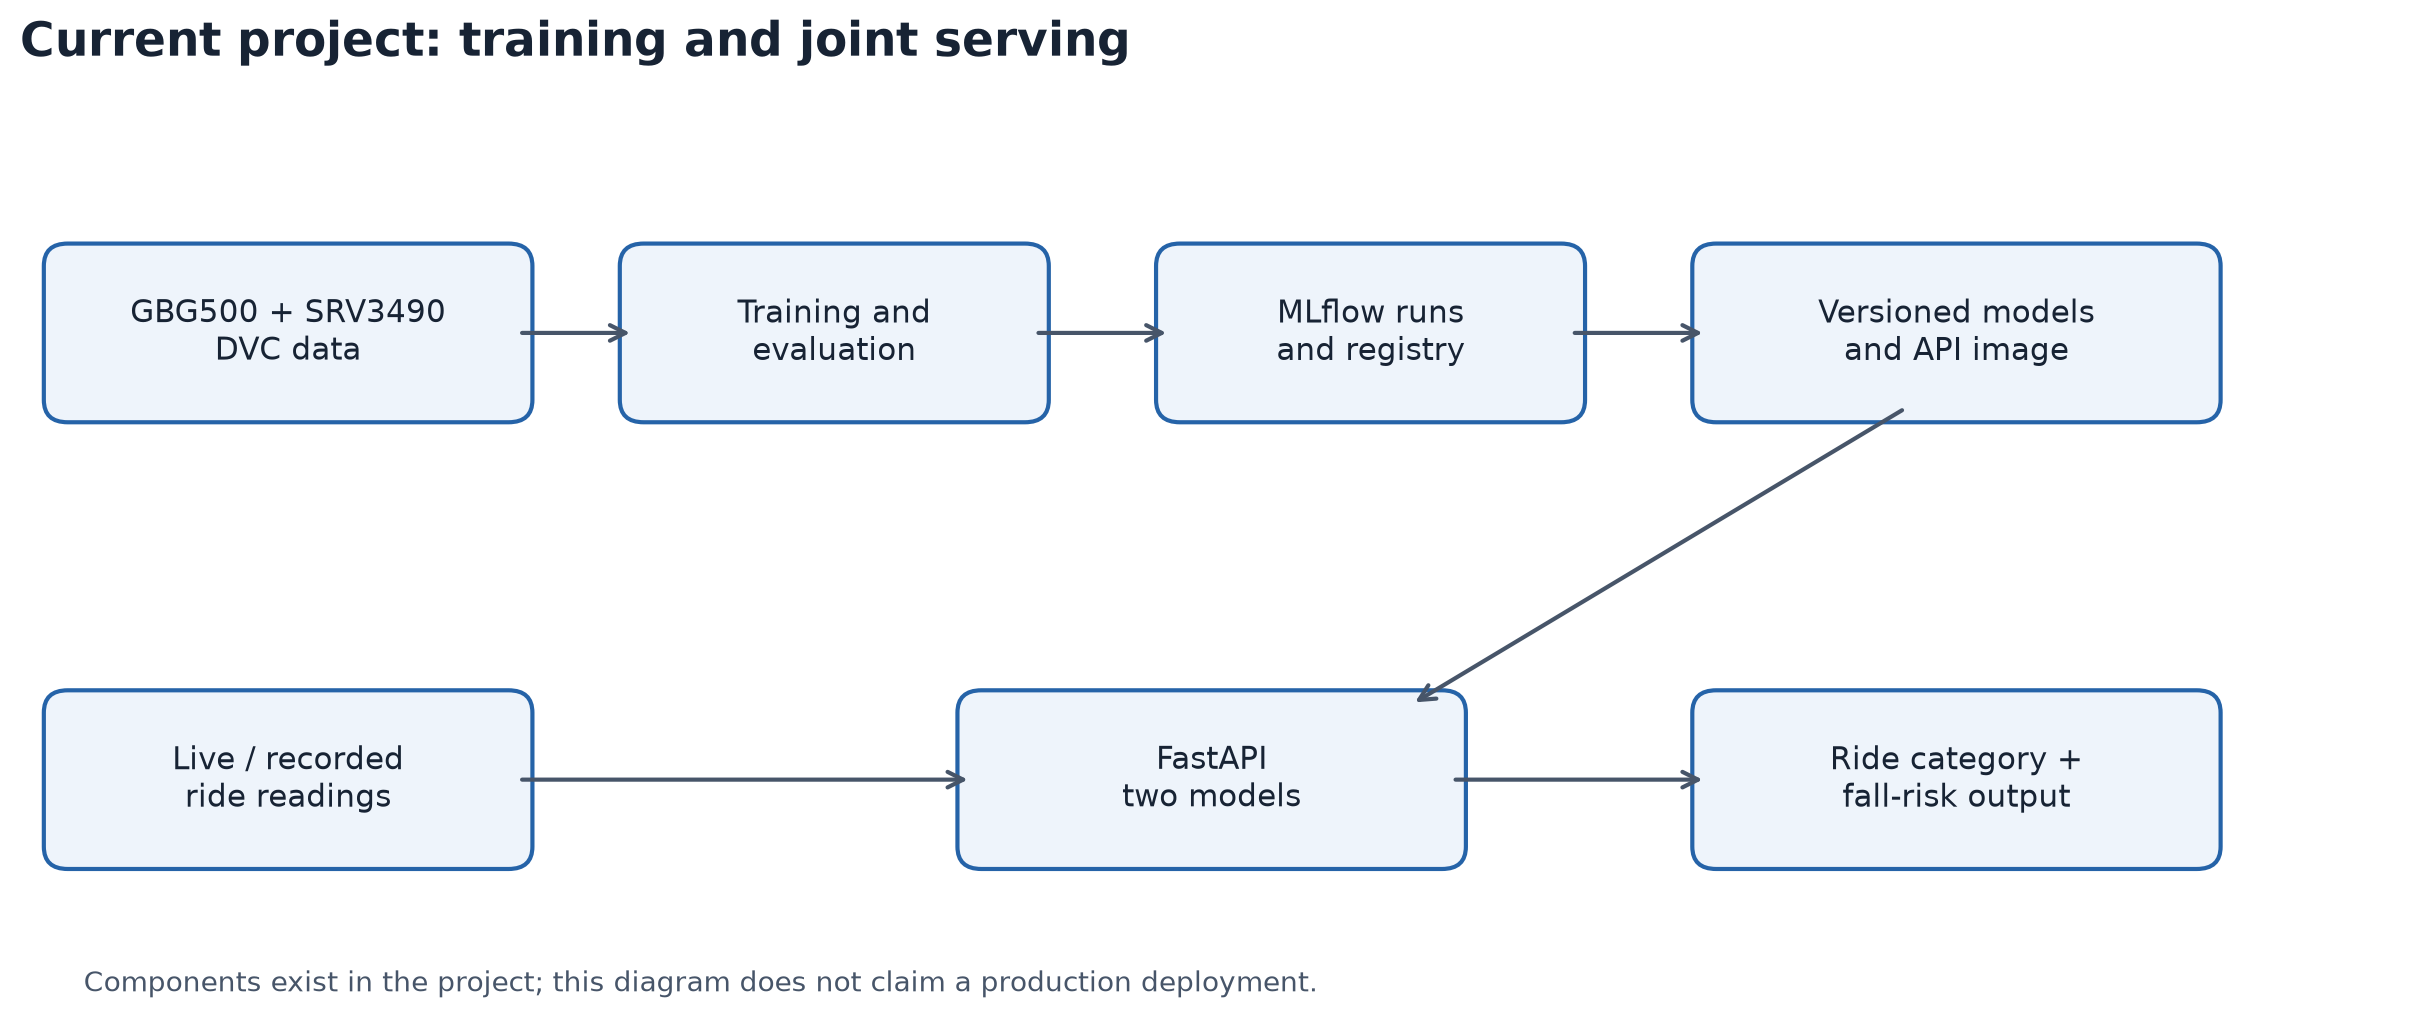

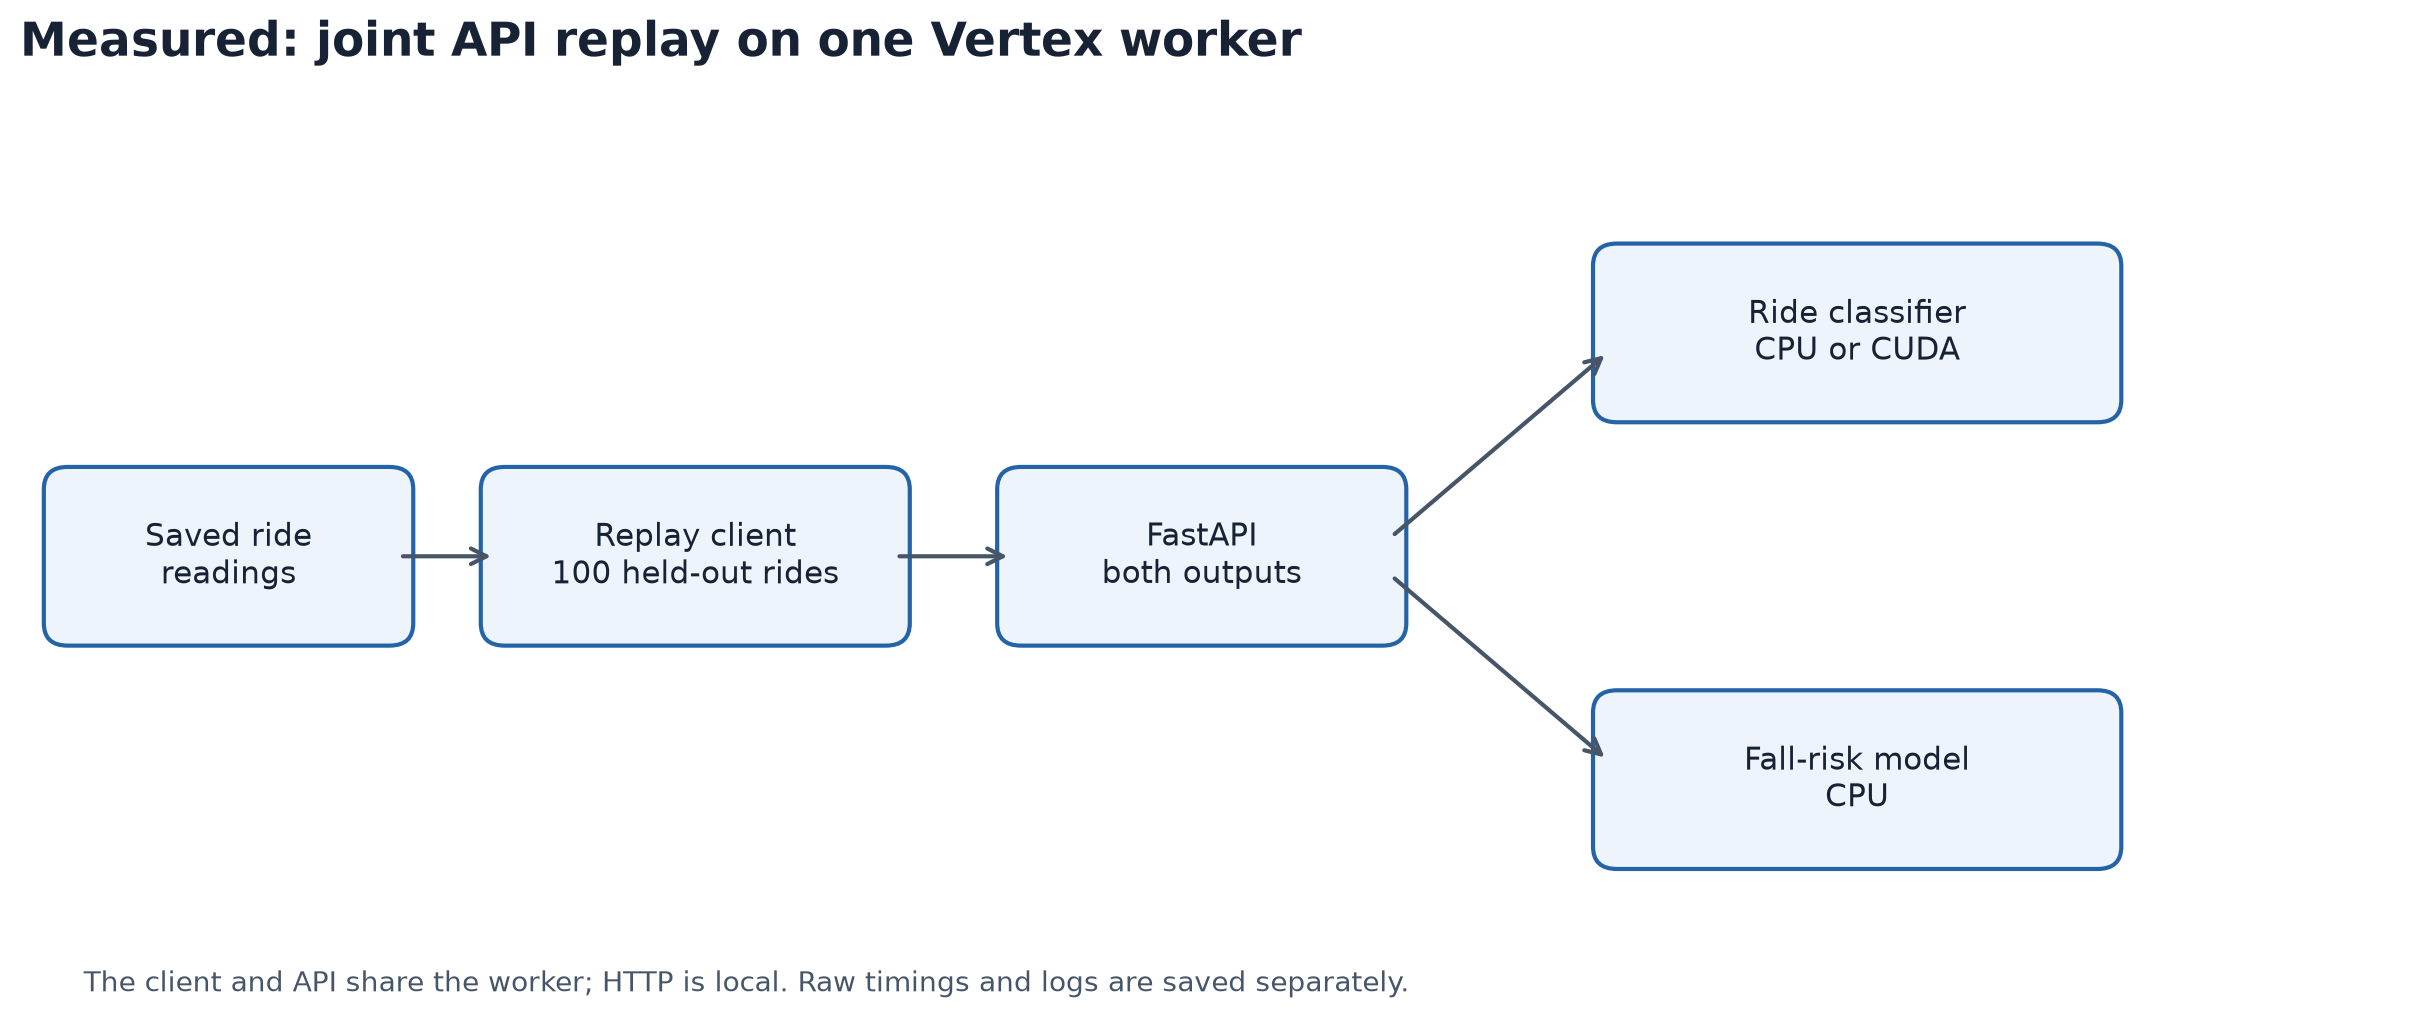

,subject,measure,value,unit,scope,source
0,GBG500,raw_readings,1529547,readings,500 rides,../architecture/inventory.md
1,GBG500,raw_parquet_size,30206760,bytes,raw file,../architecture/inventory.md
2,SRV3490,raw_readings,16892002,readings,3490 rides,../architecture/inventory.md
3,SRV3490,raw_parquet_size,268229940,bytes,raw file,../architecture/inventory.md
4,ride_classifier,serialized_model_size,193215,bytes,MLflow Python model v2,../architecture/inventory.md
5,fall_risk,serialized_model_size,9197,bytes,MLflow Python model v1,../architecture/inventory.md
6,ride_classifier,window_shape,6 x 300,values,30 seconds at 10 Hz,../architecture/inventory.md
7,ride_classifier,training_seconds_median_cpu,212.62,seconds,three Vertex same-worker runs,results/vertex-gpu-summary.md
8,ride_classifier,training_seconds_median_cuda,34.02,seconds,three Vertex same-worker runs,results/vertex-gpu-summary.md
9,ride_classifier,training_cuda_allocator_peak,29.14,MiB,allocated tensors not total VRAM,results/vertex-gpu-summary.md


In [2]:
import pandas as pd
display(Image(filename=str(root / 'ai-infrastructure' / 'architecture' / 'current-system.png')))
display(Image(filename=str(root / 'ai-infrastructure' / 'architecture' / 'measured-replay.png')))
display(pd.read_csv(evidence.HERE / 'sizing.csv'))


## What is being measured?

The service receives scooter sensor readings and returns **two different results**: the ride
category so far and the current fall-risk score. A post-ride request returns the category and
retrospective risk analysis. In the CPU/CUDA comparison the same A100 worker is used twice:
only the classifier runs on CUDA in the second case; fall-risk and preprocessing stay on CPU.
This isolates device placement, not the price of two different machine types.

The underlying sample has 100 held-out rides. Each of three measured rounds per device sends
100 post-ride requests and 200 live requests, one client at a time, after warm-up. Dots below
represent rounds, not independent machines or new datasets. Latencies include the HTTP service.


## Joint API: both outputs, one client

Each point is the p95 of one round. Each round contains 100 whole-ride and 200 live requests;
the generator shares the A100 worker with the service. CUDA applies to the classifier, while
preprocessing and fall-risk inference remain on CPU. This does not measure stream capacity.


,device,round,route,requests,mean_ms,p95_ms,mixed_requests_s,api_peak_rss_mib,peak_allocated_vram_mib,ride_macro_f1
0,cpu,1,/v1/predict,100,1232.921417,1735.638335,2.120699,810.066406,0.000000,0.51073
1,cpu,1,/v1/predict/window,200,67.322843,73.124539,2.120699,810.066406,0.000000,0.51073
2,cpu,2,/v1/predict,100,1227.775490,1761.340462,2.131013,810.066406,0.000000,0.51073
3,cpu,2,/v1/predict/window,200,66.580056,70.380723,2.131013,810.066406,0.000000,0.51073
4,cpu,3,/v1/predict,100,1229.193425,1747.268000,2.125313,810.066406,0.000000,0.51073
5,cpu,3,/v1/predict/window,200,67.415099,78.715630,2.125313,810.066406,0.000000,0.51073
6,cuda,1,/v1/predict,100,1214.425342,1725.657653,2.152962,1290.949219,3.034668,0.51073
7,cuda,1,/v1/predict/window,200,66.038308,70.135038,2.152962,1290.949219,3.034668,0.51073
8,cuda,2,/v1/predict,100,1225.025085,1752.649418,2.132716,1290.949219,3.034668,0.51073
9,cuda,2,/v1/predict/window,200,66.941843,73.127349,2.132716,1290.949219,3.034668,0.51073


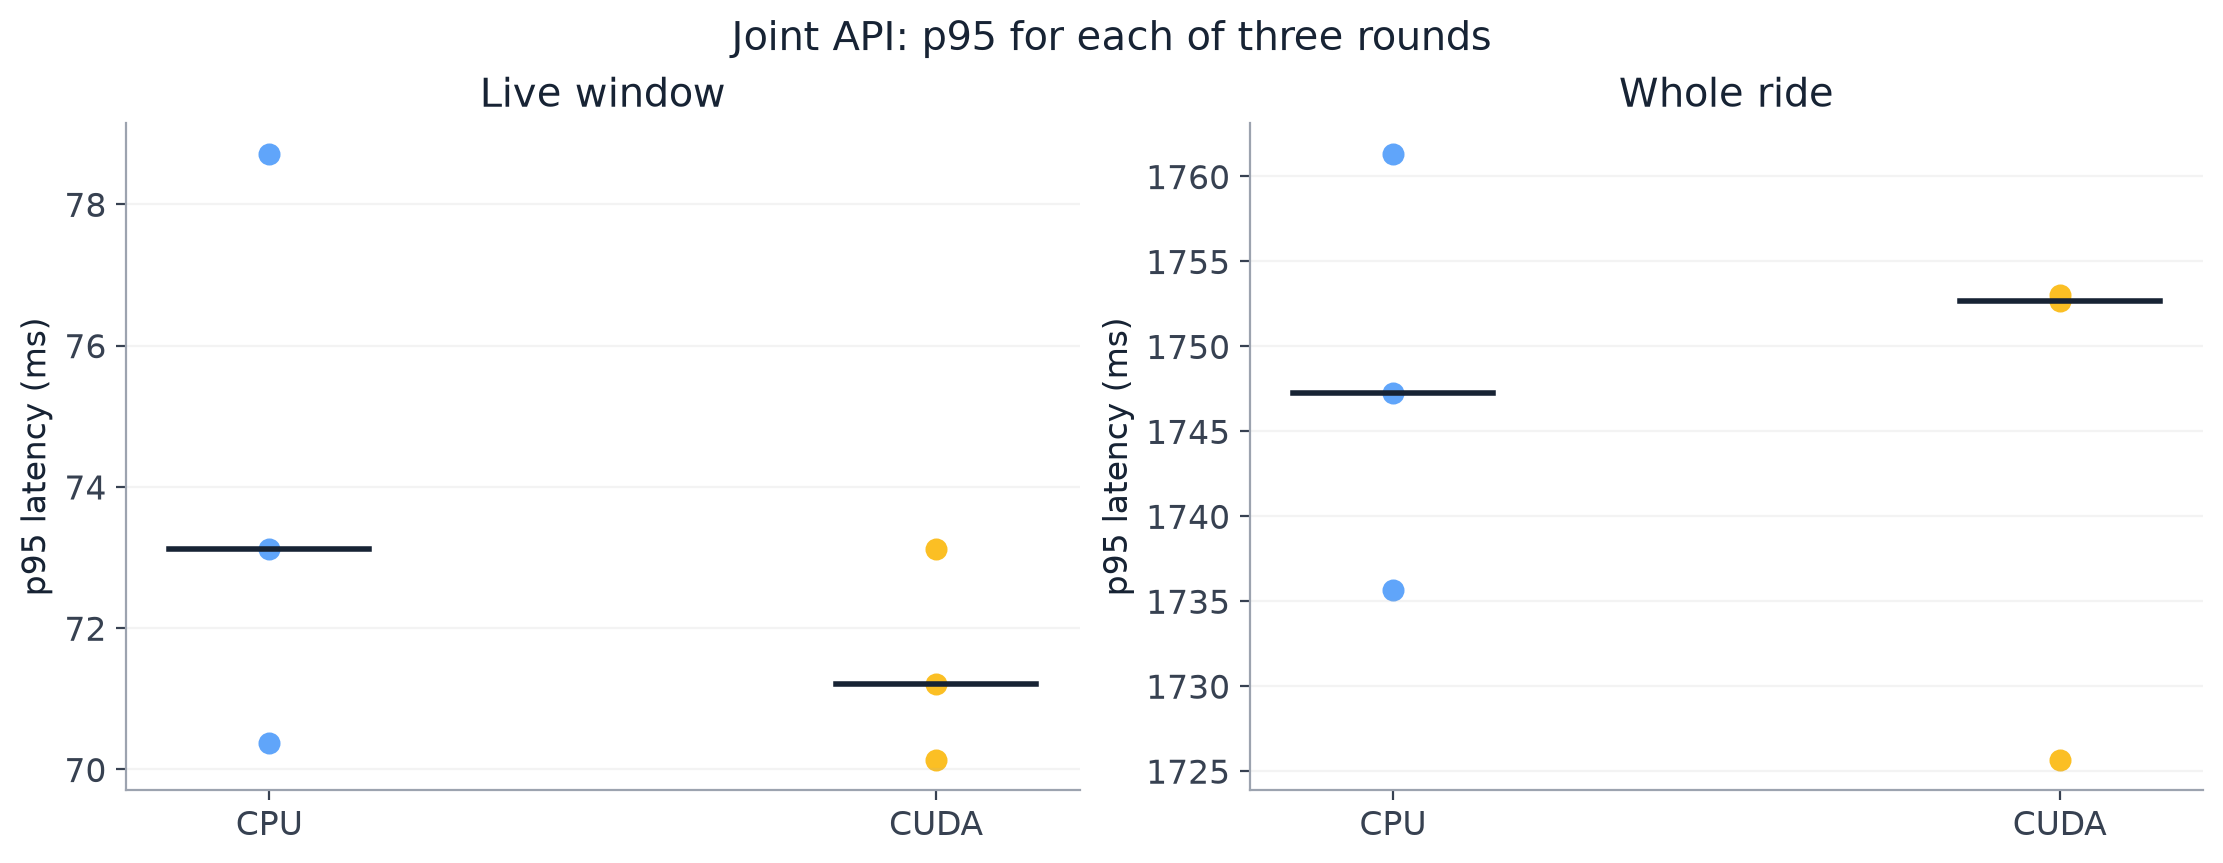

In [3]:
display(api[['device', 'round', 'route', 'requests', 'mean_ms', 'p95_ms',
             'mixed_requests_s', 'api_peak_rss_mib', 'peak_allocated_vram_mib', 'ride_macro_f1']])
display(Image(filename=str(evidence.OUTPUT / 'joint_api_p95.png')))


### Option A: live latency, on its own

This view answers how long the API takes to respond during a ride. The bar is the median of
three round-level p95 values; the dots show the rounds. A p95 means 95% of requests in that
round were no slower than the displayed value. Compare variation before claiming a speedup.


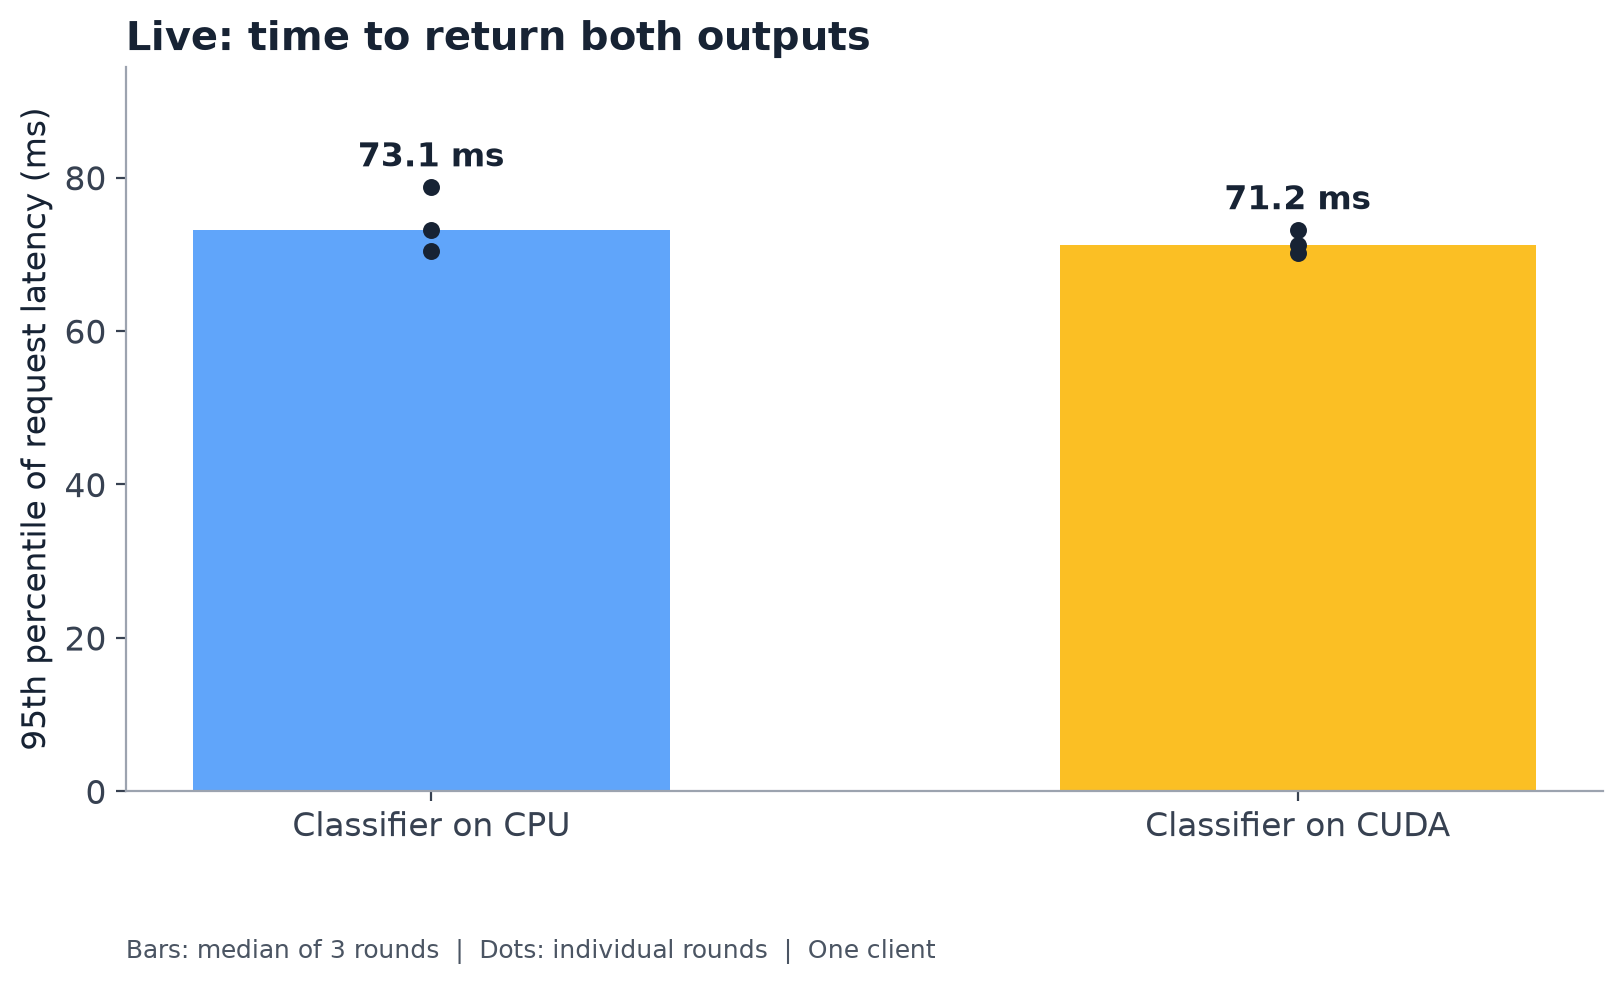

In [4]:
display(Image(filename=str(evidence.OUTPUT / 'live_latency.png')))

### Alternative: distribution of the individual live requests

The previous chart summarizes each round. This view shows all 600 requests per device; it is
useful for seeing the spread, but the repeated rides are not 600 independent examples.


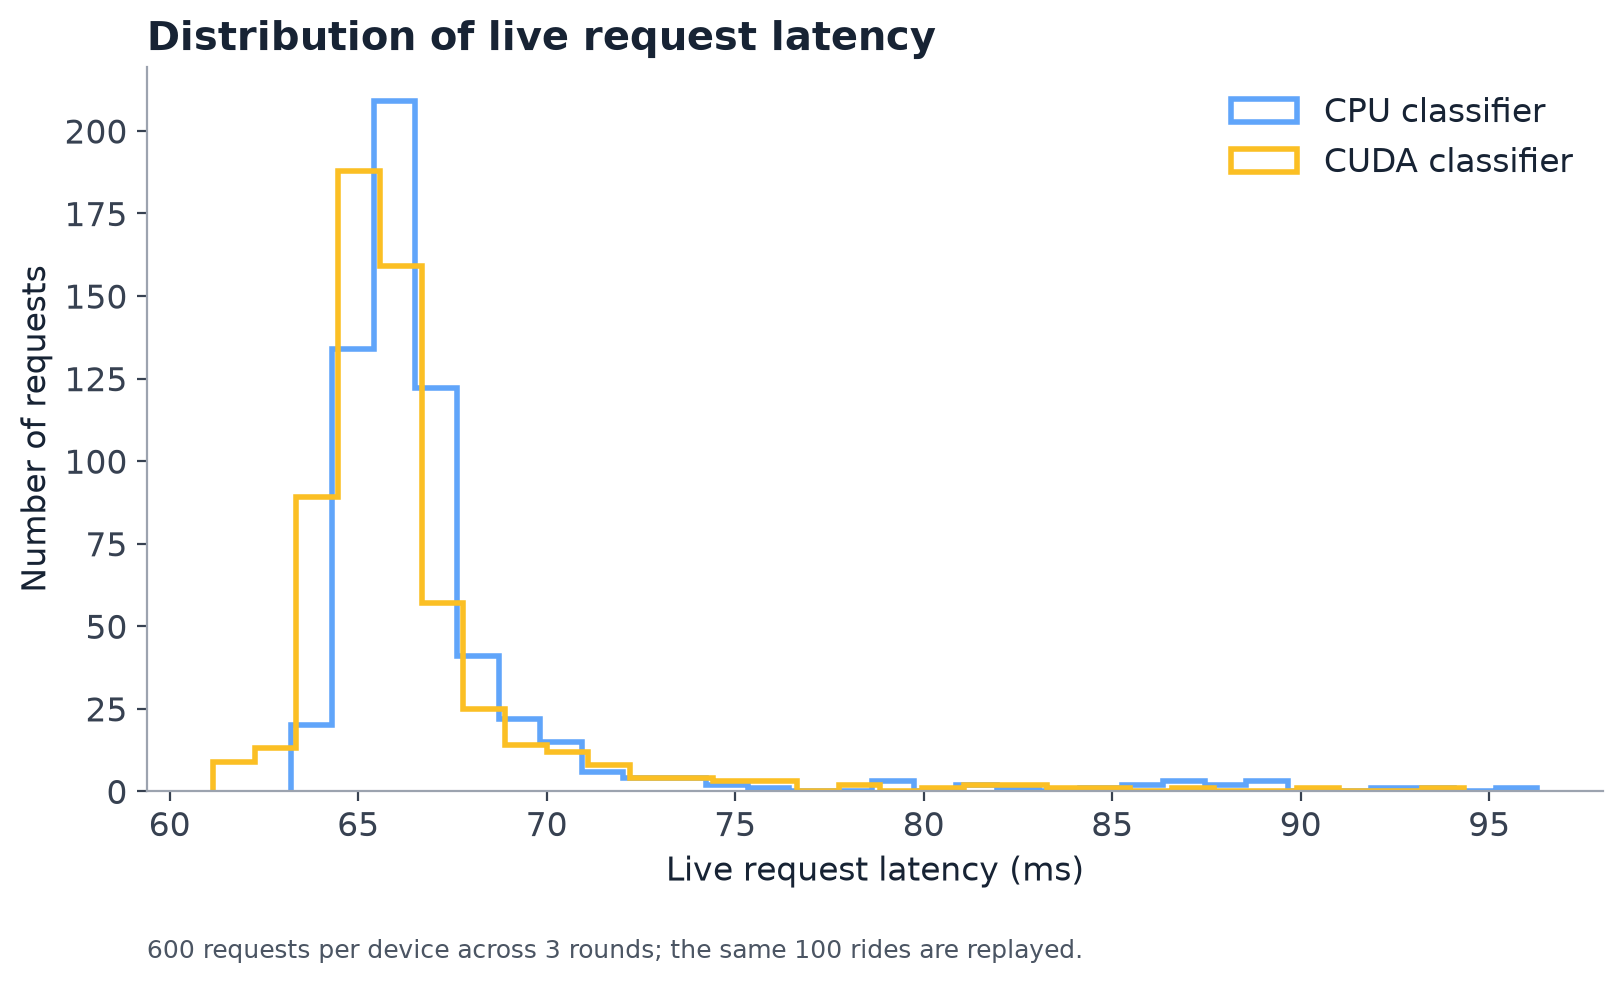

In [5]:
display(Image(filename=str(evidence.OUTPUT / 'live_latency_distribution.png')))

### Option B: post-ride latency

A whole ride contains many more readings than one live window, so these values must not be
plotted on the same scale as live latency without explanation. Fall-risk output is retrospective.


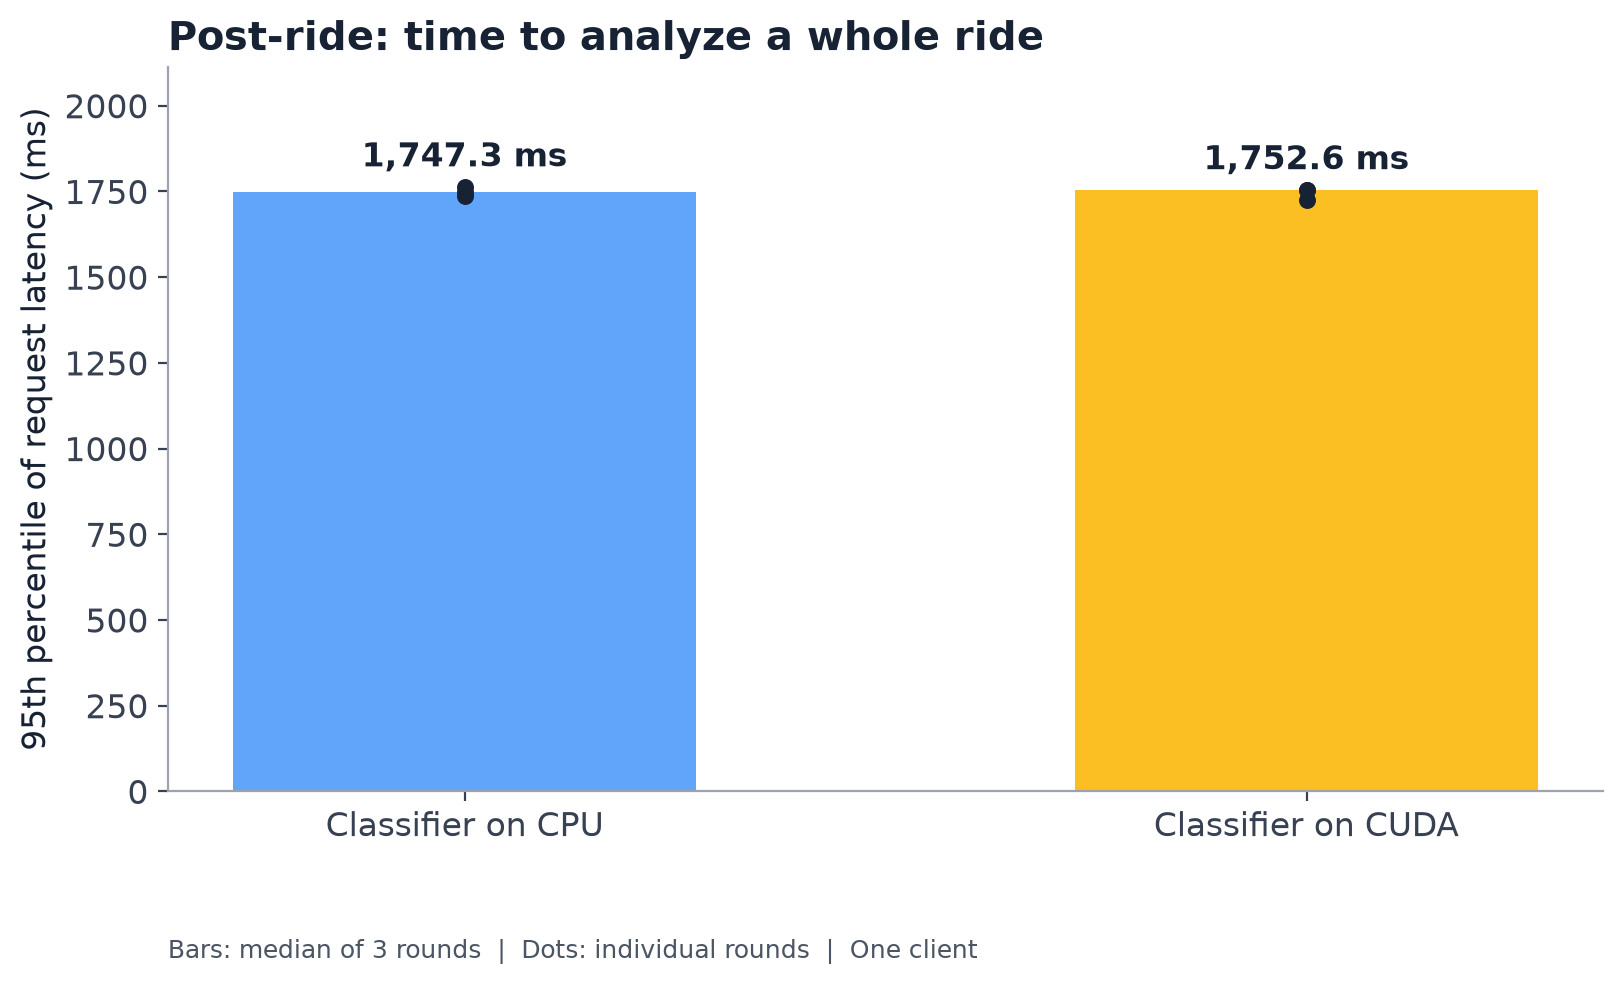

In [6]:
display(Image(filename=str(evidence.OUTPUT / 'post_ride_latency.png')))

### Option C: end-to-end host memory

This is the peak resident memory of the API process serving both models. CUDA's host memory
includes its runtime. The CUDA tensor allocator peak was 3.03 MiB; that is not total VRAM
reserved by the process and does not replace a total GPU-memory measurement.


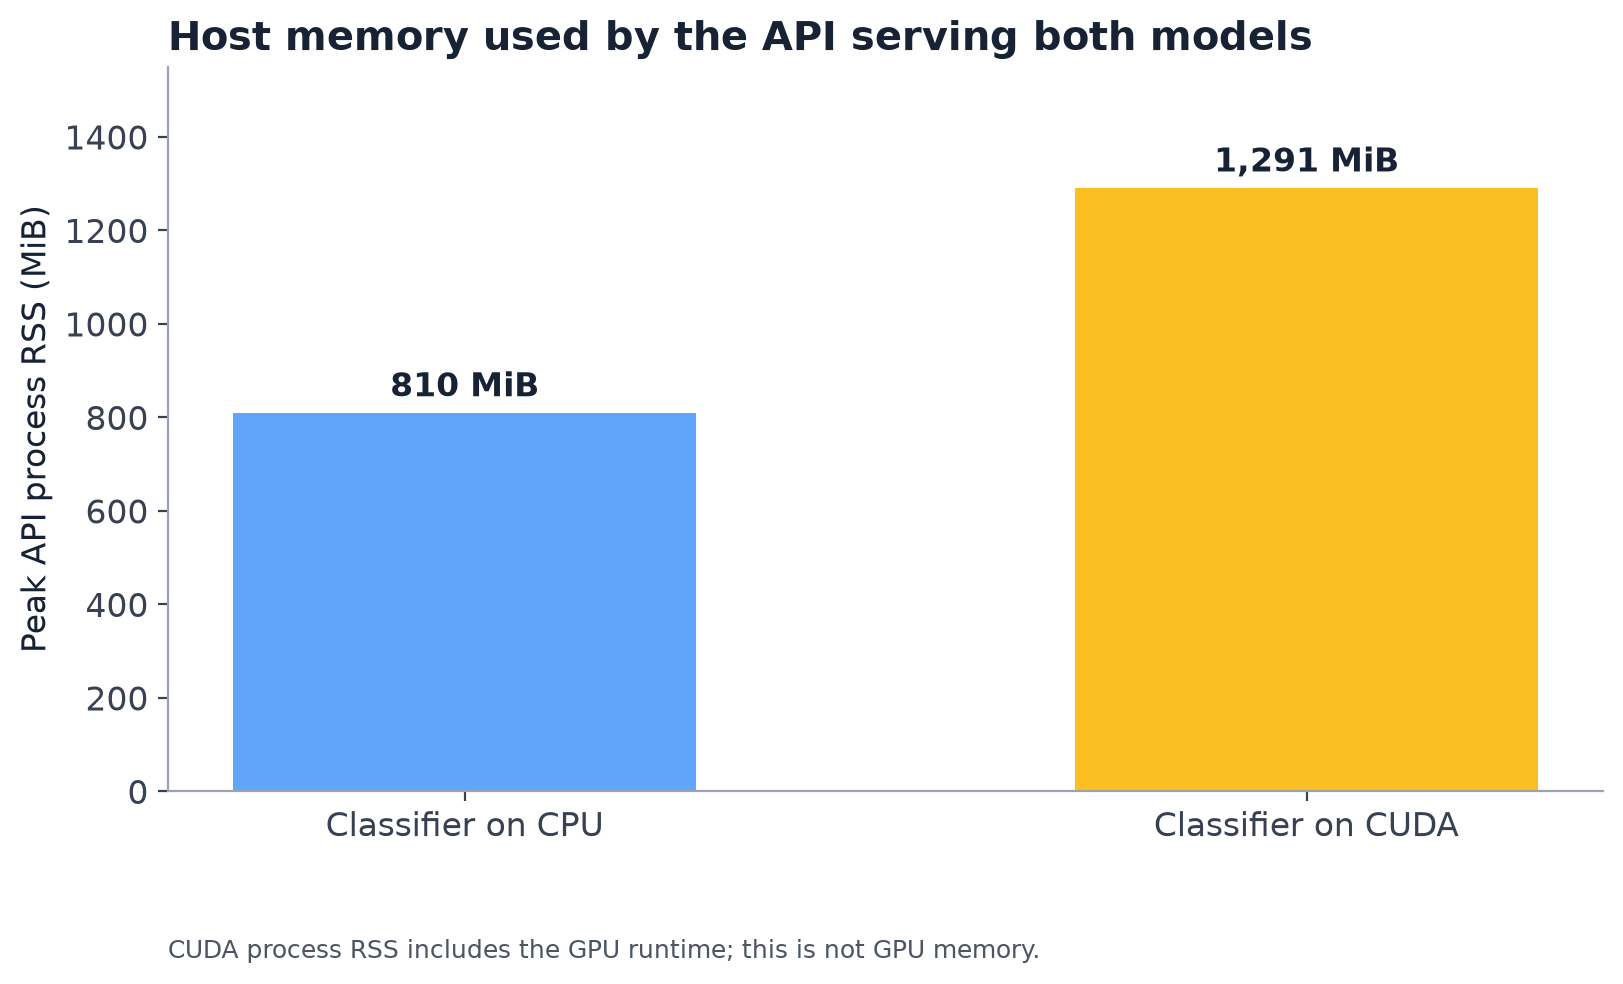

In [7]:
display(Image(filename=str(evidence.OUTPUT / 'api_host_memory.png')))

### GPU memory: what was actually captured

The chart shows only peak tensors allocated by PyTorch during the joint API test and the
classifier training runs. It excludes reserved memory, CUDA runtime and other GPU usage, so it
is a lower bound, not a measurement of total process VRAM or a complete machine sizing.


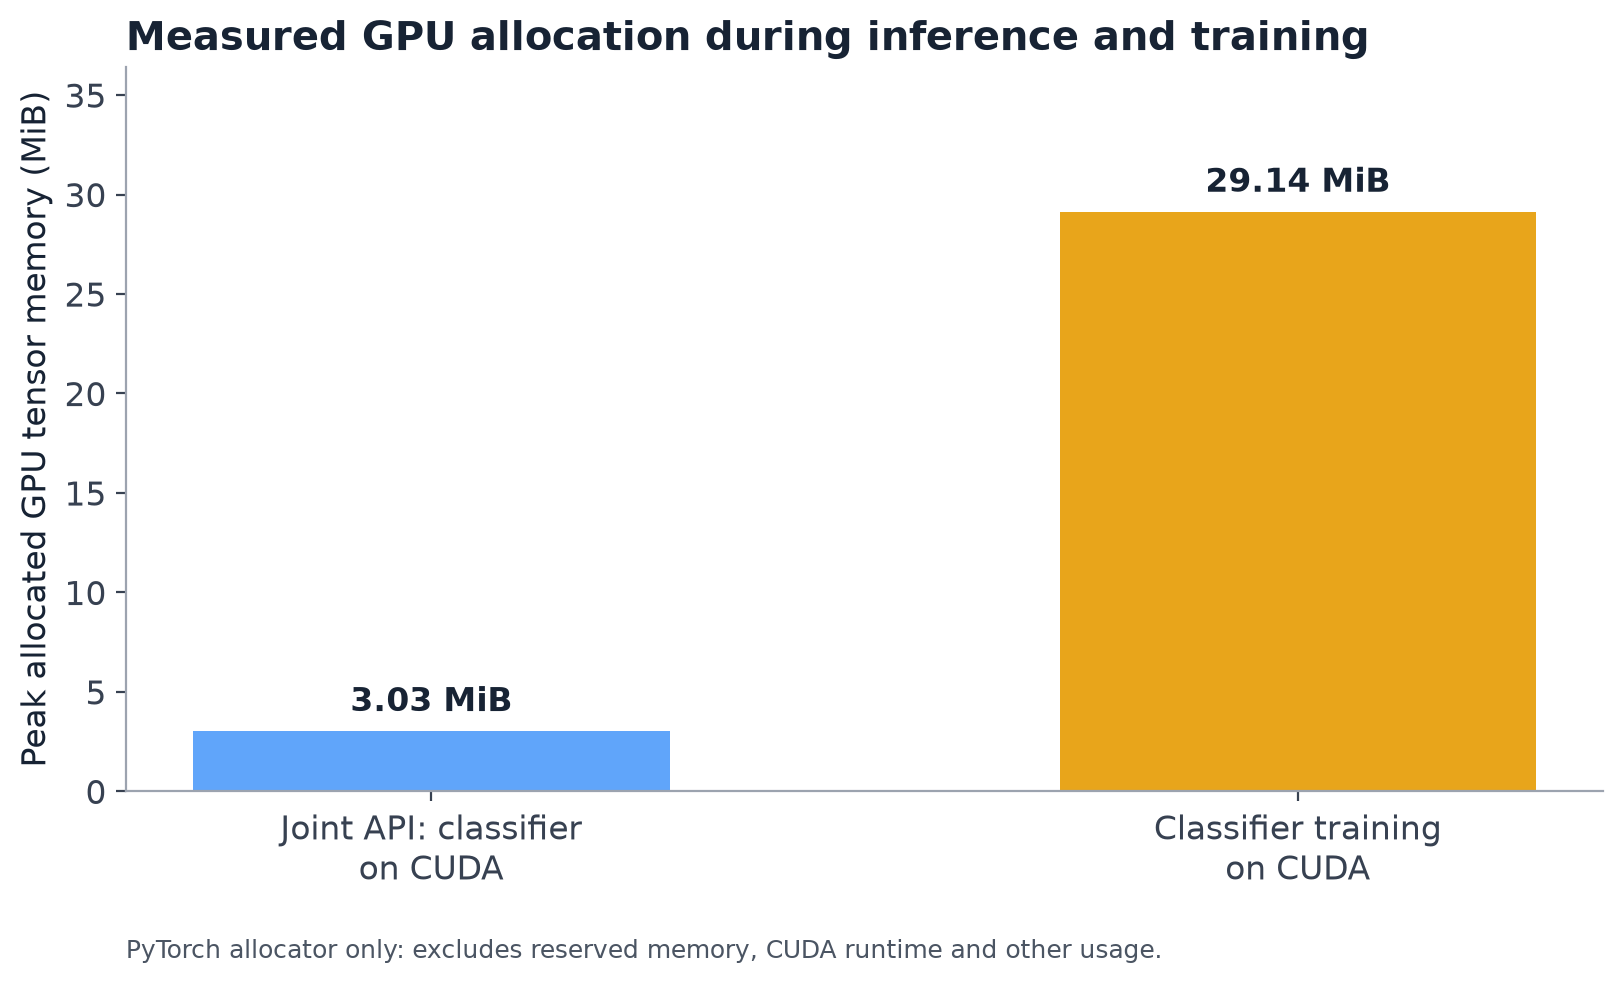

In [8]:
display(Image(filename=str(evidence.OUTPUT / 'gpu_tensor_allocation.png')))

## Ride classifier training

The timer covers the classifier training stage and model logging, not data preparation or the
subsequent golden evaluation. GPU allocator memory excludes reserved memory and other CUDA usage.
The separate fall-risk CPU run includes different work and should not be compared directly.


,device,round,elapsed_s,peak_process_rss_mib,peak_allocated_vram_mib,golden_macro_f1,stage_run_id
0,cpu,1,198.624427,1579.671875,0.000000,0.470961,be74c5a15c8c4dc18290ad526d11093a
1,cpu,2,212.620403,1580.507812,0.000000,0.470961,61ce16b4c2e749f0974dc84838e52f7a
2,cpu,3,232.539648,1571.921875,0.000000,0.470961,33dc5b41054a4b848df149de5474f3d5
3,cuda,1,33.643319,2174.507812,29.138672,0.503843,ed5b4d380af6414681df8c6d88b0166c
4,cuda,2,34.053442,2175.539062,29.138672,0.572552,38cd4d3477234686ada8f63eff911f4f
5,cuda,3,34.020026,2182.542969,29.138672,0.438304,759f2320a63a4baa88c409f6f5405460


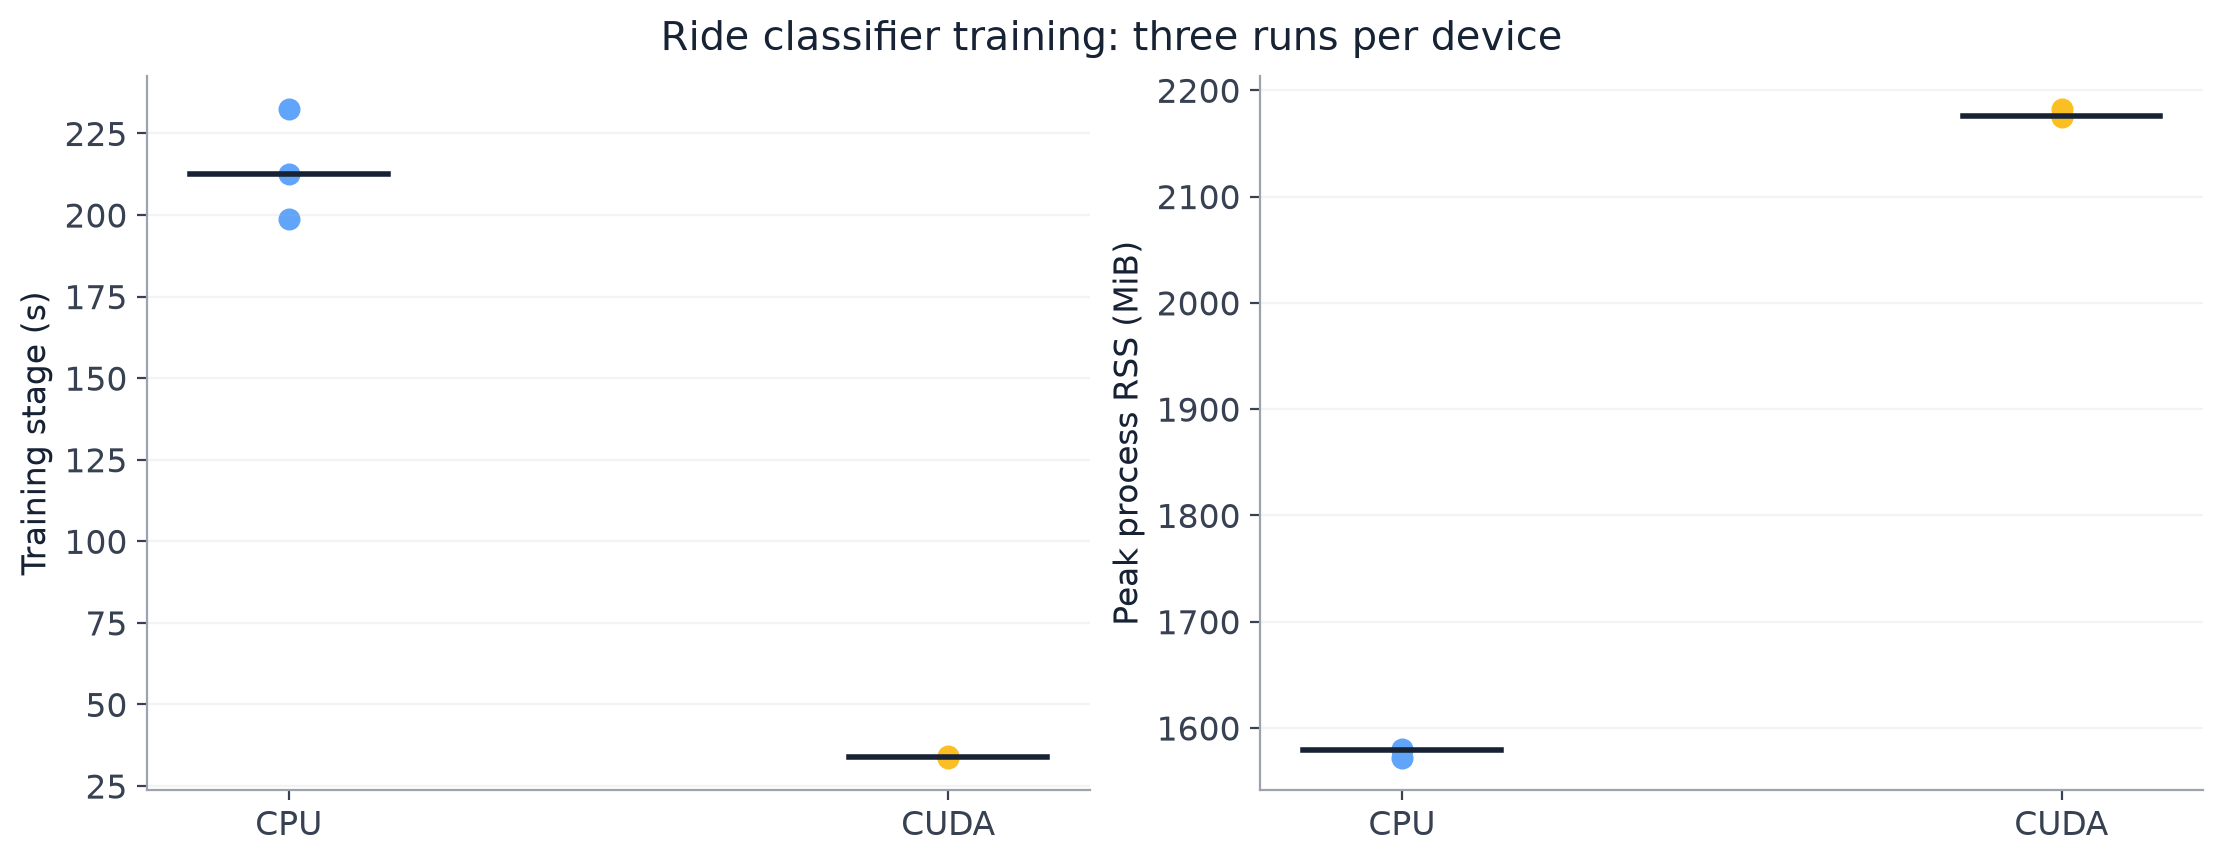

In [9]:
display(training)
display(Image(filename=str(evidence.OUTPUT / 'classifier_training.png')))


### Alternative: training duration without the memory panel

The stage includes five folds and a final fit, plus model logging. The three GPU training runs
had different golden macro-F1 scores: faster training is not evidence of identical model quality.


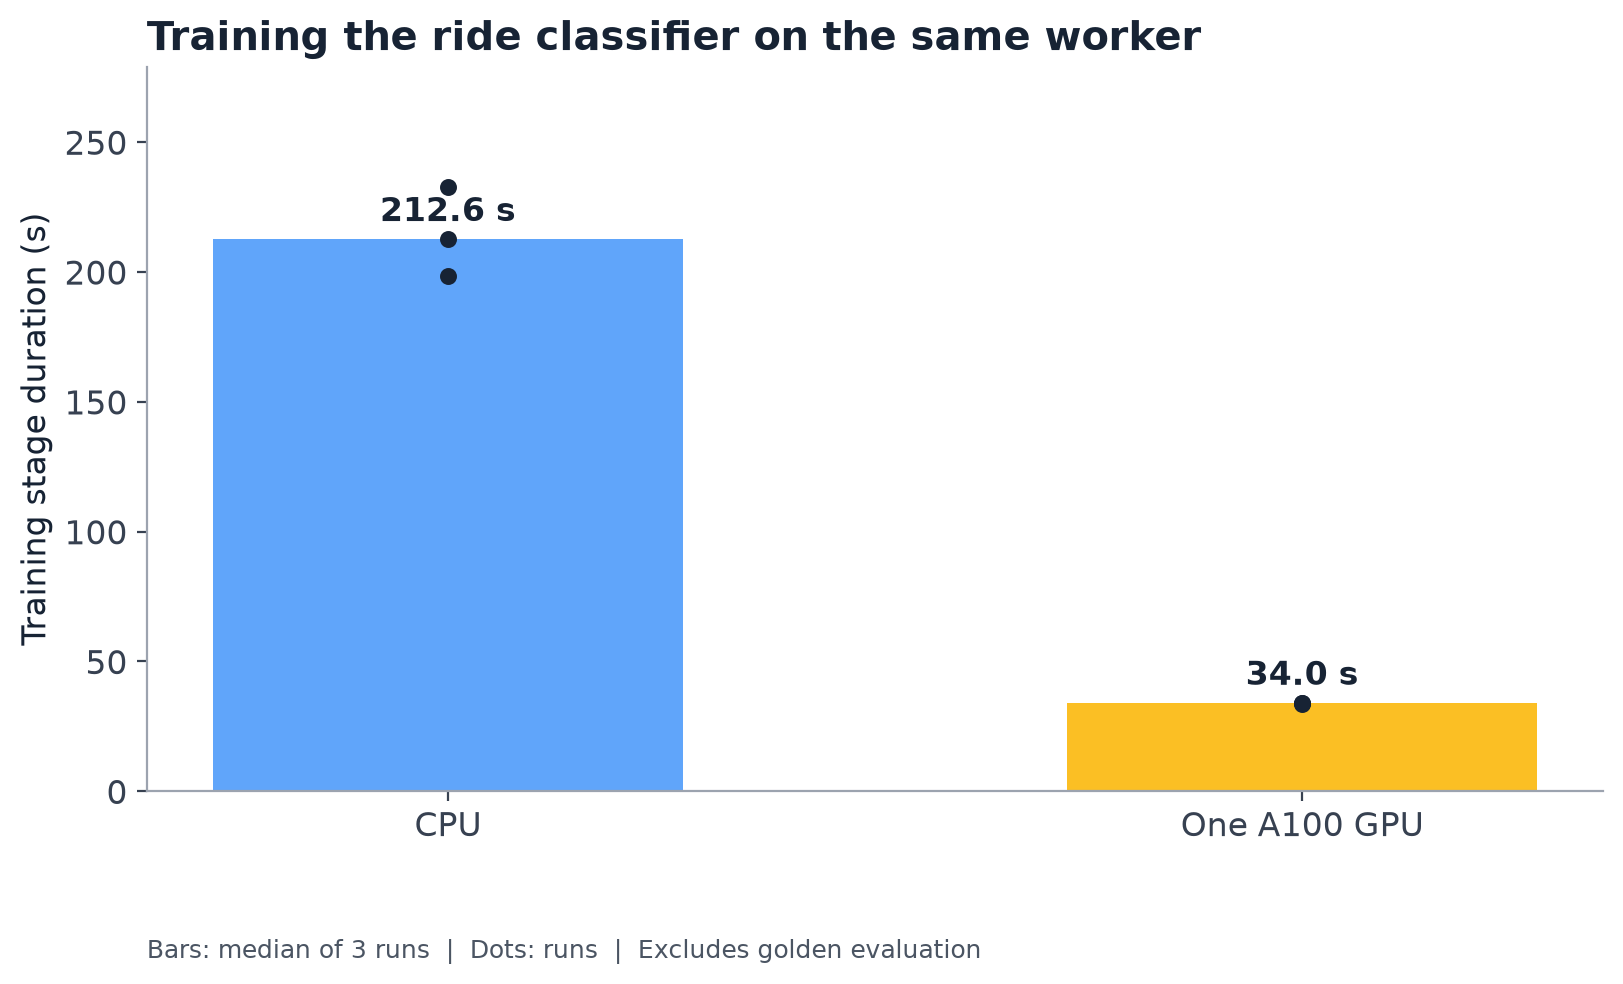

In [10]:
display(Image(filename=str(evidence.OUTPUT / 'training_duration.png')))

### Training quality check

The faster GPU training rounds did not produce identical models. This plot prevents interpreting
training time in isolation from the held-out quality of the resulting classifier.


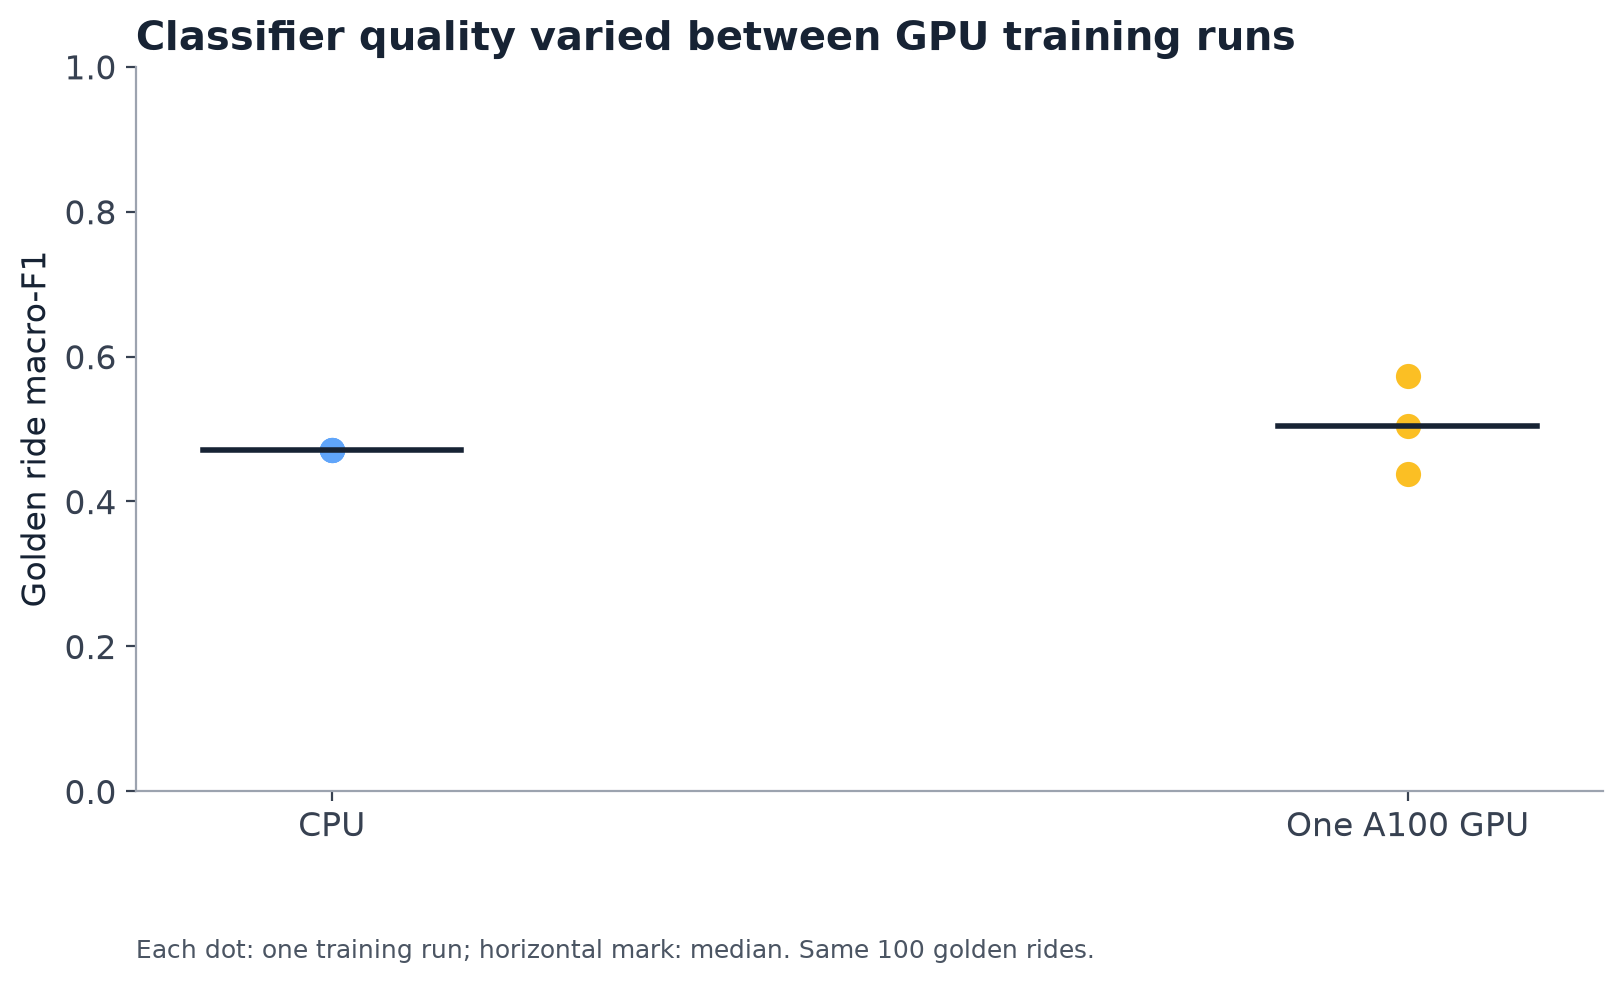

In [11]:
display(Image(filename=str(evidence.OUTPUT / 'training_quality.png')))

### Fall-risk model: a separate CPU observation

This full laptop run covers feature construction, training, evaluation and logging, so it is
not directly comparable to the classifier-stage timings above. It is a single observation.


In [12]:
import json
fall = json.loads((evidence.RESULTS / 'training-fall-risk-local-1.json').read_text())
fall_quality = json.loads((evidence.RESULTS / 'training-fall-risk-local-1-metrics.json').read_text())
print(f"Full fall-risk stage: {fall['elapsed_s'] / 60:.1f} min; "
      f"sampled process-tree peak: {fall['sampled_process_tree_peak_rss_mib']:.0f} MiB.")
print(f"Held-out paired AUC: {fall_quality['held_out_paired_auc']:.3f} "
      f"across {int(fall_quality['held_out_n_groups'])} groups.")


Full fall-risk stage: 21.6 min; sampled process-tree peak: 2982 MiB.
Held-out paired AUC: 0.888 across 205 groups.


## An exploratory mixed-load test

This separate CPU test combines whole-ride and live requests. It uses a closed-loop client on
the same host as the service and only one run at each concurrency level. It helps show behavior
under this test, but cannot establish the number of live rides supported in production.


,clients,live_p95_ms,mixed_requests_s
0,1,111.398013,1.643687
1,2,535.583150,1.340427
2,4,1196.512385,1.105689


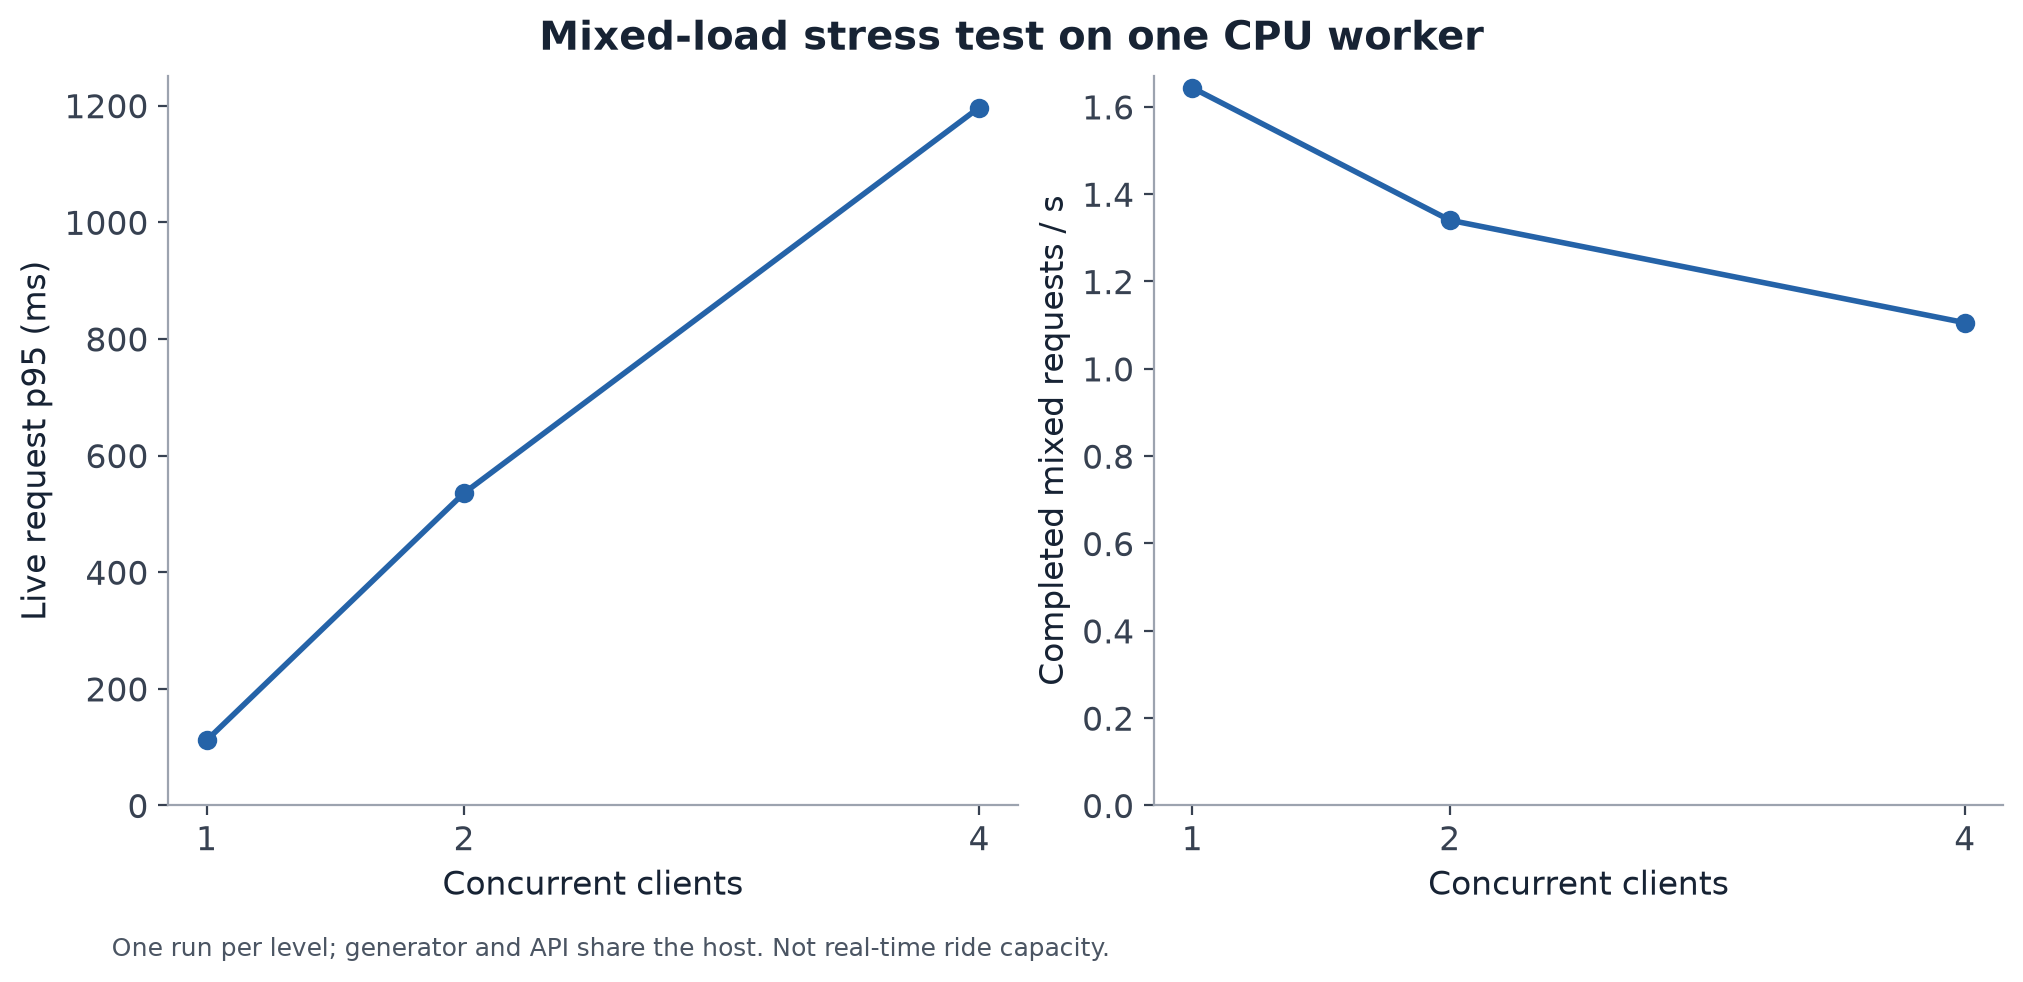

In [13]:
import pandas as pd
display(pd.read_csv(evidence.HERE / 'mixed-load-results.csv'))
display(Image(filename=str(evidence.OUTPUT / 'mixed_load.png')))


## Optimization: PyTorch and ONNX Runtime on CPU

This separate experiment tests the classifier **network only**, with already prepared windows;
it is not a measurement of the full two-model API. The same frozen weights, inputs and two CPU
threads were used for both runtimes. Each round has 20 warm-ups and 200 timed calls per batch;
three rounds alternate runtime order. Results include the conversion of ONNX outputs to tensors.


,runtime,round,batch,mean_ms,p95_ms,process_rss_mib,windows_per_s
0,onnx,1,1,0.230877,0.289160,495.343750,4331.319945
1,onnx,1,8,1.017074,1.561880,495.398438,7865.697159
2,onnx,1,32,4.468409,6.342160,495.406250,7161.385633
3,onnx,1,128,15.212711,18.907125,503.285156,8414.016411
4,onnx,2,1,0.256405,0.313770,503.328125,3900.079963
5,onnx,2,8,1.423574,1.689220,503.425781,5619.658682
6,onnx,2,32,5.449818,6.276830,503.476562,5871.755179
7,onnx,2,128,19.780791,23.306305,503.570312,6470.924242
8,onnx,3,1,0.275820,0.354650,504.375000,3625.559430
9,onnx,3,8,1.387646,1.726800,504.484375,5765.161192


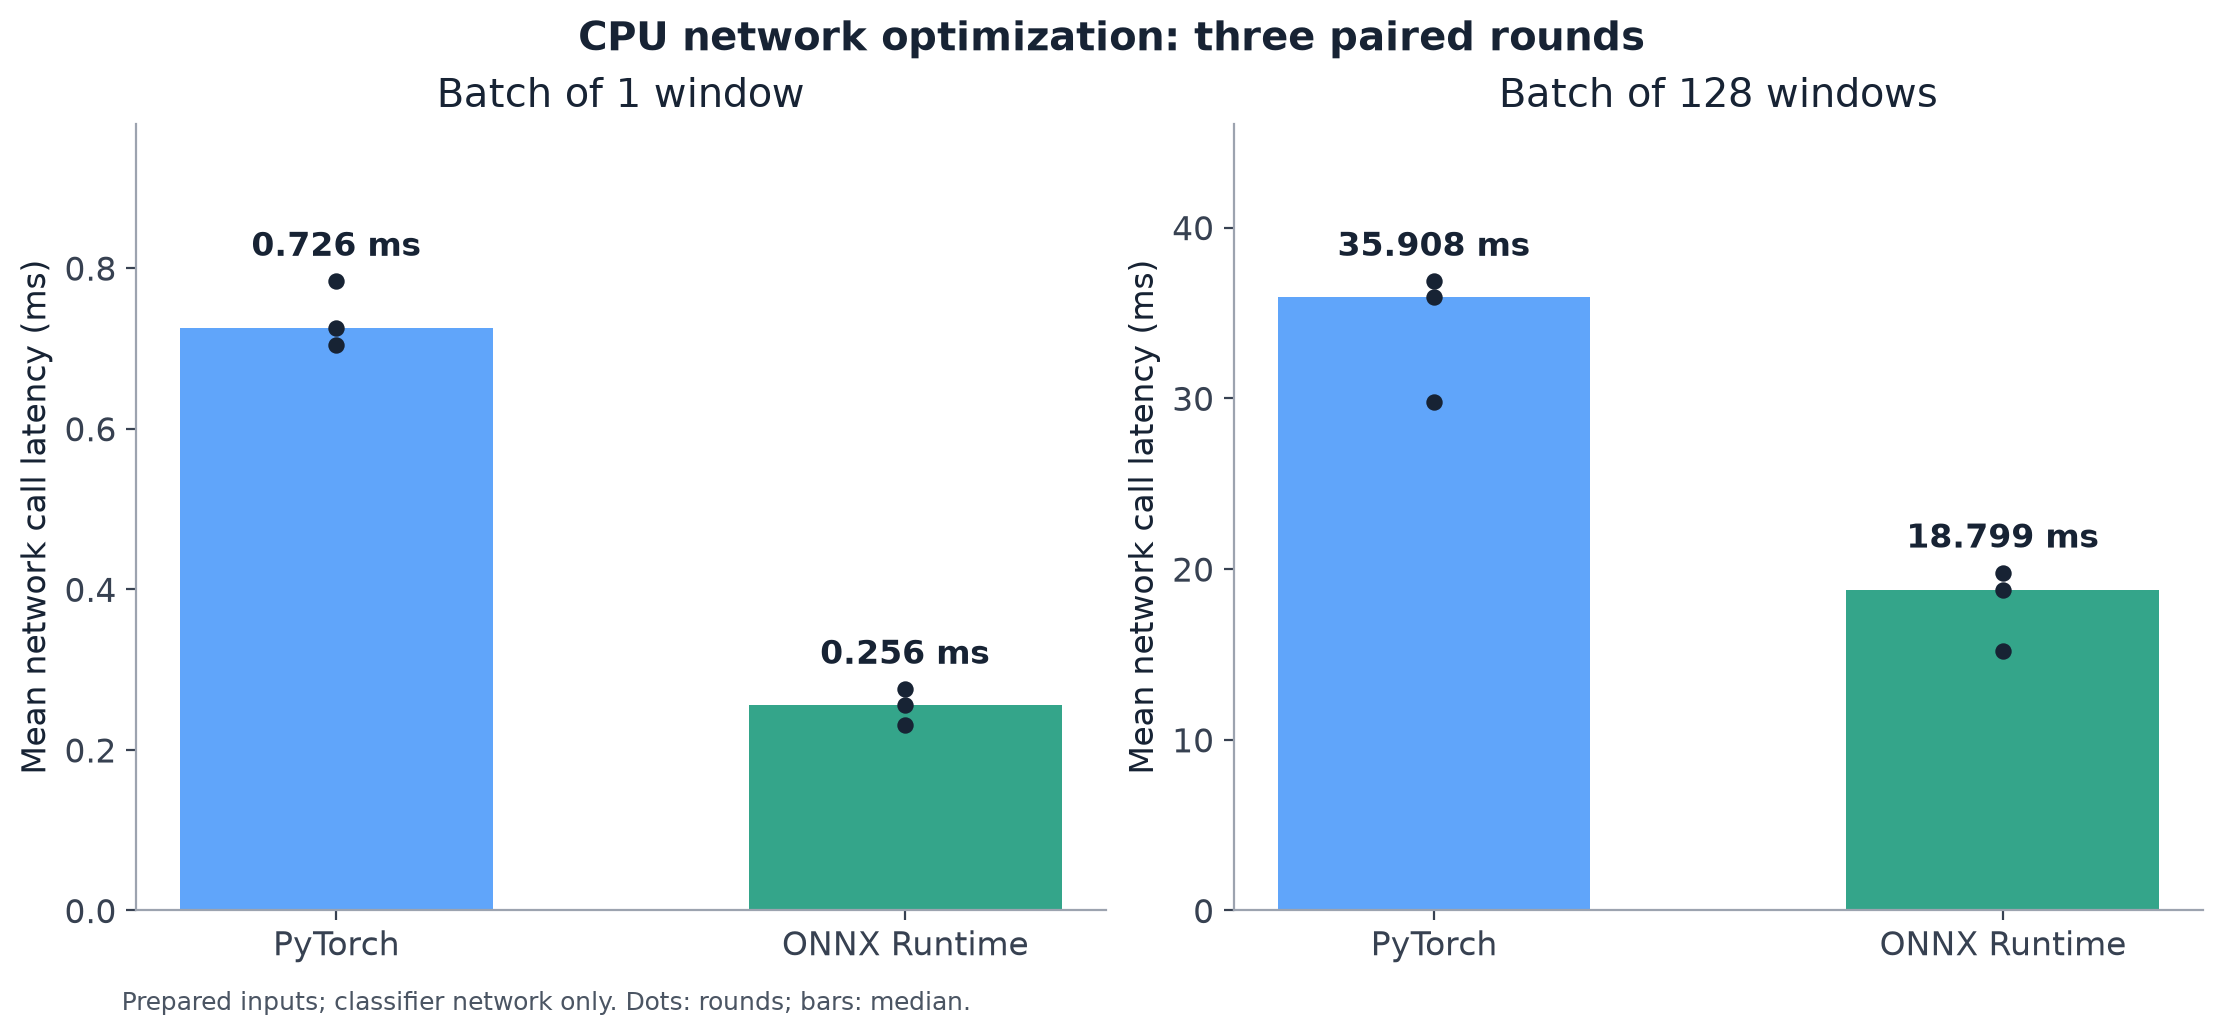

Window prediction agreement: 100.0%; ride macro-F1: PyTorch 0.5107, ONNX 0.5107.
RSS is process-wide with both runtimes loaded; it does not isolate either runtime.


In [14]:
opt_dir = root / 'ai-infrastructure' / 'optimization' / 'results'
if (opt_dir / 'summary.csv').exists():
    optimization = pd.read_csv(opt_dir / 'summary.csv')
    display(optimization)
    display(Image(filename=str(evidence.OUTPUT / 'onnx_latency.png')))
    meta = json.loads((opt_dir / 'environment.json').read_text())
    print(f"Window prediction agreement: {meta['window_argmax_agreement']:.1%}; "
          f"ride macro-F1: PyTorch {meta['pytorch_ride_macro_f1']:.4f}, ONNX {meta['onnx_ride_macro_f1']:.4f}.")
    print('RSS is process-wide with both runtimes loaded; it does not isolate either runtime.')
else:
    print('Optimization results are not available yet; see optimization/protocol.md.')


### Alternative: network throughput as batch size grows

These are windows per second in an isolated network call, not end-to-end API requests per second.
The logarithmic horizontal scale makes the tested batch sizes visible.


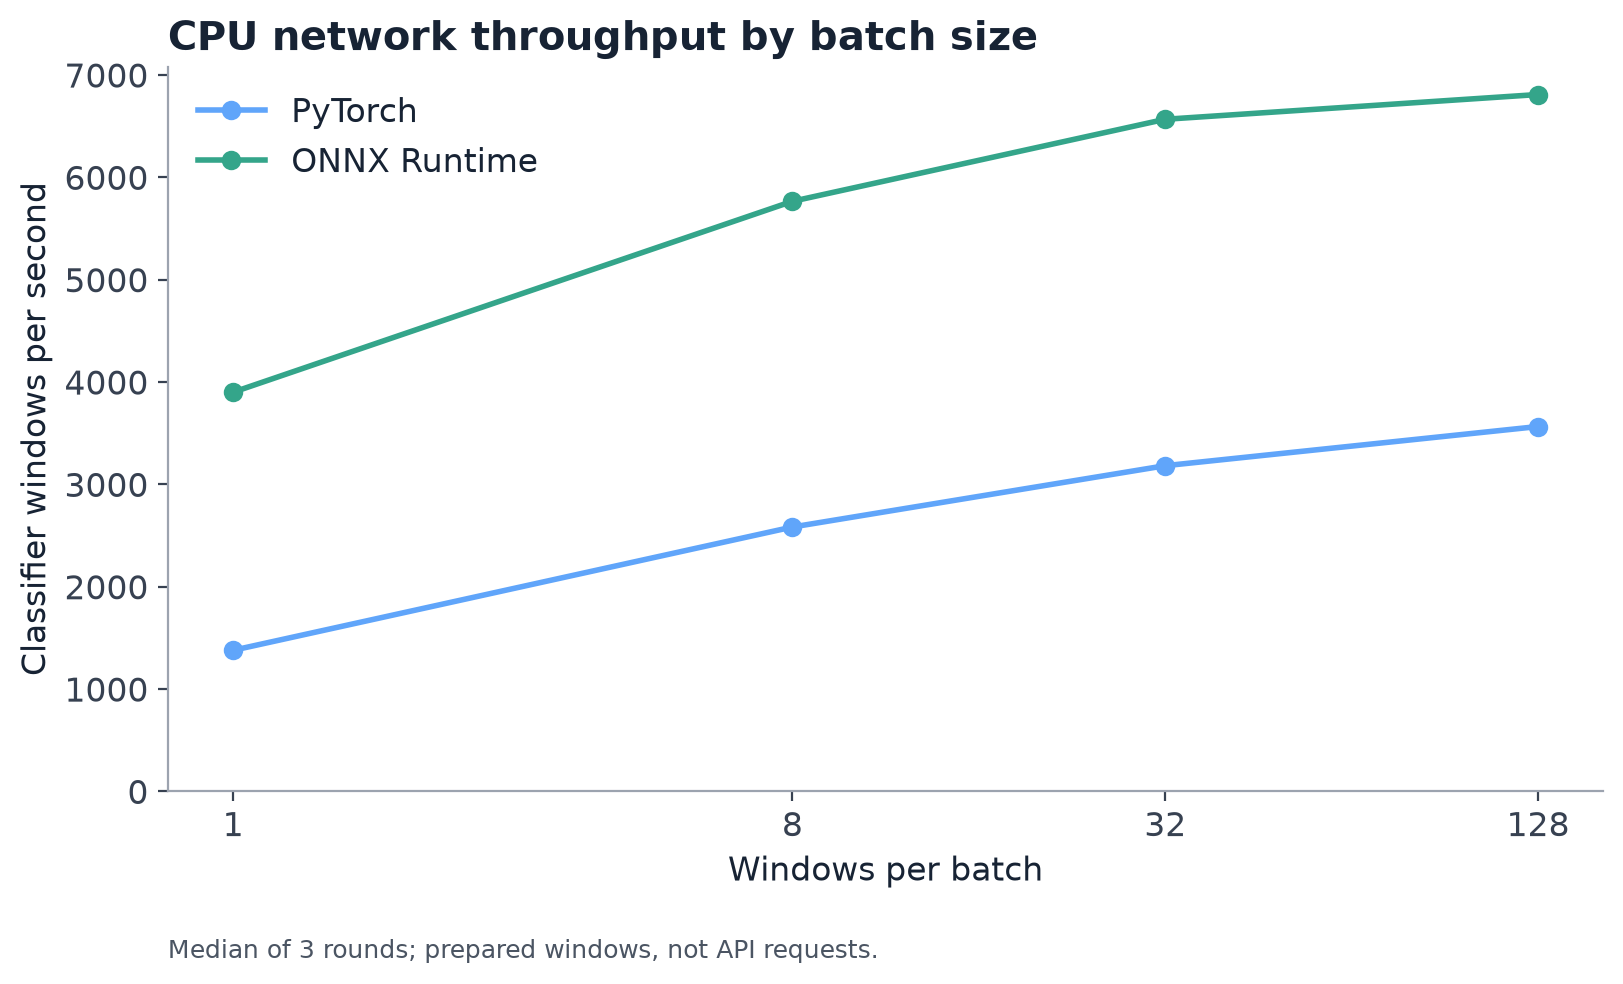

In [15]:
if (evidence.OUTPUT / 'onnx_throughput.png').exists():
    display(Image(filename=str(evidence.OUTPUT / 'onnx_throughput.png')))


## Next analyses

The baseline does not establish performance at concurrent real-time load. Review the resource
sizing, cost assumptions, recovery and proposed architecture before selecting evidence for the
presentation. See the [execution tasks](../../specs/001-final-deliverable/cloud-infra-tasks.md).
